# 第二轮融合实验：Mamba 和 ViT 接在 YOLO26s 的哪一层？

第一轮中，第四组把 Mamba 接在 L13，第五组在此基础上给 L10 加了一个小型 ViT。在同一组验证图上，艇（USV）的 AP50 从 81.48% 升到 84.93%，车（UGV）的 AP50 从 92.26% 降到 91.08%。车的 AP50–95 从 77.55% 降到 71.79%。本轮想弄清楚，保留艇的这一表现时，能否通过调整特征的去向或 ViT 的位置，改善车的检测。

### 第一轮的两个对照

训练集有 622 张图，验证集有 93 张。下表取自种子为 0 的两次训练，均使用各自的 `best.pt` 复评。[第一轮实验结果，「已完成模型」工作表](training/实验结果汇总.xlsx)

| 第一轮对照 | UGV AP50 | UGV AP50–95 | USV AP50 | USV AP50–95 | Overall mAP50 | Overall mAP50–95 |
|---|---:|---:|---:|---:|---:|---:|
| 第四组 · L13 Mamba | **92.26%** | **77.55%** | 81.48% | 60.54% | 86.87% | **69.04%** |
| 第五组 · L13 Mamba + L10 ViT | 91.08% | 71.79% | **84.93%** | **64.95%** | **88.00%** | 68.37% |

### 14 个候选怎么比较

每行固定 Mamba 的位置和接收它的路径，每列固定 ViT 的位置。横着看可以比较 ViT，竖着看可以比较 Mamba 的接法。

| P4 位置 | 哪些连接使用融合特征 | 无 ViT | P5 L10 ViT | P5 L22 ViT |
|---|---|---|---|---|
| Backbone L6 | 主路径和跳连 | N01 | N02 | N03 |
| Backbone L6 | 仅跳连 | N04 | N05 | N06 |
| Neck L13 | 主路径和跳连 | 第四组（已有） | 第五组（已有） | N07 |
| Neck L13 | 仅跳连 | N08 | N09 | N10 |
| Neck L13 | 仅主路径 | N11 | N12 | 本轮留空 |

建议先看 L13 的六组。第四组、N08、N11 都只用 Mamba，分别把融合特征送往双路径、仅跳连、仅主路径。第五组、N09、N12 在相同的三种接法上都加了 L10 ViT。按接法逐对比较，就能看到加 ViT 后车和艇的 AP 各怎样变化。

在项目根目录打开本文件，选择 `.venv-cuda` 内核并运行全部单元格。Notebook 会在 CPU 上创建并检查 12 个模型，最后保存配置。三人的 100 轮训练从文末的 PowerShell 命令启动。

In [1]:
from pathlib import Path
from io import BytesIO
import subprocess, sys, tempfile
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Image, display
import torch

from models.phase2 import (CONFIG, GROUPS, PROJECT, WEIGHTS, COCO, baseline_config,
                           definitions, export, sha256)
from models.phase2_layers import EDGES, SPECS, EdgeScan, make_detector
from ultralytics import YOLO

if Path.cwd().resolve() != PROJECT or not WEIGHTS.is_file():
    raise RuntimeError("请从仓库根目录启动 Notebook，并按 README 准备 yolo26s.pt")
assert sha256(WEIGHTS) == COCO
torch.set_num_threads(2)
torch.manual_seed(0)
defs = definitions()
verified = {}
baseline = make_detector(baseline_config(), nc=2, weights=YOLO(str(WEIGHTS), verbose=False).model).eval()
sample = torch.rand((1, 3, 640, 640), generator=torch.Generator().manual_seed(0))
with torch.inference_mode():
    reference = baseline(sample)
fonts = {f.name for f in font_manager.fontManager.ttflist}
mpl.rcParams["font.family"] = next((f for f in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"] if f in fonts), "sans-serif")
print(f"已载入 {len(defs)} 个结构定义。输入尺寸 {tuple(sample.shape)}，类别为 UGV 和 USV。")

Overriding model.yaml nc=80 with nc=2


已载入 12 个结构定义。输入尺寸 (1, 3, 640, 640)，类别为 UGV 和 USV。


## 特征从哪里来，到哪里去

输入为 640 × 640 时，两个候选 Mamba 层的特征图都是 40 × 40。L6 位于骨干网络，主路径进入 L7 下采样，跳连进入 L12 拼接。L13 已经融合了两个尺度的特征，主路径进入 L14 上采样，跳连进入 L18 拼接。自底向上融合时，L17 和 L20 依次下采样，L21 将 L20 的输出与 L10 的特征拼接。P3、P4、P5 最终分别由 L16、L19、L22 送入 L23 检测头。

每组图的左侧画 P4。原特征记为 `x`，经过 Mamba 并与原特征相加后记为 `y = x + α·Mamba(x)`。双路径共用同一份 `y`。单路径只给选定的连接送 `y`，另一条仍然接收 `x`。右侧画 P5。L10 的输出会参与后续多尺度融合，L22 的输出直接进入检测头。图的排版借鉴了论文中先看整网、再展开局部模块的做法。[QuadMamba 图 2，NeurIPS 2024](https://proceedings.neurips.cc/paper_files/paper/2024/file/d592bfaedf2f0861d7084cceba208d18-Paper-Conference.pdf#page=4)

### 每组用什么条件检查

四向 Mamba 的扫描宽度为 64，状态维度为 8。小型 ViT 用一层编码器，嵌入维度为 256，含 4 个注意力头。两个残差分支的门控系数都从 0 开始。

1. 将模型与使用相同权重的 YOLO26s 逐元素比较。门控为 0 时，两者的检测输出应完全一致。
2. 在内存中把门控暂设为 0.2，读取主路径和跳连的输入，检查每条连接实际收到的是 `x` 还是 `y`。
3. 保存一份临时模型，在新的 Python 进程中加载并重建网络。用同一个 128 × 160 的随机输入张量比较两次预测。检查结束后清理临时权重，正式训练使用统一的 YOLO26s COCO 初始权重。

下面先给出整网连接图。绘图和检查函数的代码可以展开查看，每个候选模型的创建代码单独列在该组图前。

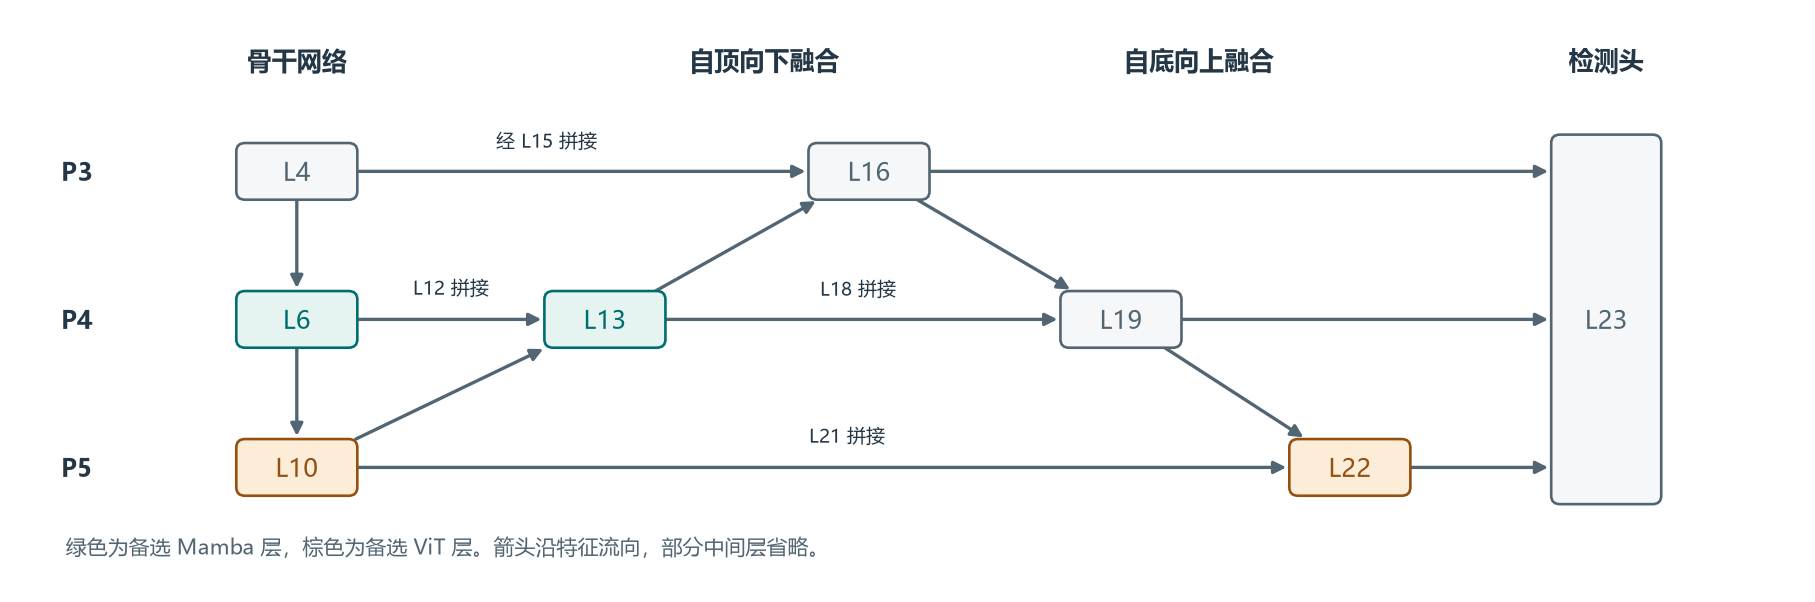

In [2]:
from matplotlib.patches import FancyBboxPatch

INK, GRAY = "#243747", "#526572"
TEAL, PALE_TEAL = "#006E70", "#E5F4F0"
OCHRE, PALE_OCHRE = "#955011", "#FCEDD8"
PAPER, LINE = "#F5F7F8", "#CFD9DD"

def canvas(height, ymax):
    fig, ax = plt.subplots(figsize=(11, height))
    fig.subplots_adjust(left=.015, right=.985, top=.98, bottom=.03)
    ax.set(xlim=(0, 16), ylim=(0, ymax))
    ax.axis("off")
    return fig, ax

def label(ax, x, y, text, size=10, color=INK, align="center", bold=False):
    ax.text(x, y, text, ha=align, va="center", color=color, fontsize=size,
            fontweight="bold" if bold else "normal", linespacing=1.2, zorder=4)

def box(ax, x, y, w, h, text, fill=PAPER, edge=GRAY, size=10):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0,rounding_size=.08",
                                facecolor=fill, edgecolor=edge, linewidth=1.15, zorder=3))
    label(ax, x, y, text, size, edge)

def arrow(ax, points, color=GRAY, raw=False):
    xs, ys = zip(*points)
    if len(points) > 2:
        ax.plot(xs[:-1], ys[:-1], color=color, lw=1.45, ls="--" if raw else "-", zorder=1)
    ax.annotate("", xy=points[-1], xytext=points[-2], zorder=2,
                arrowprops=dict(arrowstyle="-|>", mutation_scale=11, color=color, lw=1.45,
                                linestyle="--" if raw else "-", shrinkA=0, shrinkB=1.3))

def show_figure(fig):
    buf = BytesIO()
    fig.savefig(buf, format="png", dpi=165, facecolor="white")
    plt.close(fig)
    display(Image(data=buf.getvalue(), width=1000))

def draw_network():
    fig, ax = canvas(3.65, 5.45)
    for x, name in [(2.45,"骨干网络"), (6.7,"自顶向下融合"), (10.65,"自底向上融合"), (14.35,"检测头")]:
        label(ax, x, 4.98, name, 11, bold=True)
    for y, scale in [(3.93,"P3"), (2.52,"P4"), (1.11,"P5")]:
        label(ax, .45, y, scale, 11, bold=True)
    nodes = {"L4":(2.45,3.93), "L6":(2.45,2.52), "L10":(2.45,1.11),
             "L13":(5.25,2.52), "L16":(7.65,3.93), "L19":(9.94,2.52), "L22":(12.02,1.11)}
    for source, target in [("L4","L6"),("L6","L10"),("L4","L16"),("L6","L13"),
                           ("L10","L13"),("L13","L16"),("L16","L19"),("L13","L19"),
                           ("L19","L22"),("L10","L22")]:
        x1,y1 = nodes[source]
        x2,y2 = nodes[target]
        dx,dy = x2-x1,y2-y1
        frac = 1/max(abs(dx)/.55, abs(dy)/.27)
        arrow(ax, [(x1+dx*frac,y1+dy*frac),(x2-dx*frac,y2-dy*frac)])
    for layer in ("L16","L19","L22"):
        x,y = nodes[layer]
        arrow(ax, [(x+.55,y),(13.85,y)])
    box(ax,14.35,2.52,1,3.52,"L23",size=11)
    for layer,(x,y) in nodes.items():
        fill, edge = (PALE_TEAL,TEAL) if layer in ("L6","L13") else (
            (PALE_OCHRE,OCHRE) if layer in ("L10","L22") else (PAPER,GRAY))
        box(ax,x,y,1.1,.54,layer,fill,edge,11)
    for x,y,text in [(4.72,4.22,"经 L15 拼接"),(3.85,2.82,"L12 拼接"),(7.55,2.81,"L18 拼接"),
                     (7.45,1.41,"L21 拼接")]:
        label(ax,x,y,text,8.5)
    label(ax,.35,.35,"绿色为备选 Mamba 层，棕色为备选 ViT 层。箭头沿特征流向，部分中间层省略。",9,GRAY,"left")
    show_figure(fig)

def draw_routes(key):
    anchor, route, vit = SPECS[key]
    main, skip = EDGES[anchor]
    fig, ax = canvas(3.25, 4.8)
    label(ax,.25,4.40,"a   P4 特征送往哪里",11,align="left",bold=True)
    place = "无 ViT" if vit is None else f"残差 ViT 接在 L{vit}"
    label(ax,8.98,4.40,"b   P5 的两个接入位置",11,align="left",bold=True)
    ax.plot([8.67,8.67],[.46,4.47],color=LINE,lw=1)
    label(ax,.25,3.91,f"{key}   /   {'骨干网络' if anchor==6 else '特征融合网络'} L{anchor}",9,GRAY,"left")
    label(ax,8.98,3.91,place,9,OCHRE if vit else GRAY,"left")
    center, up, down = 2.15, 3.15, 1.12
    box(ax,1.12,center,1.72,.75,f"L{anchor} 输出\n原特征 x")
    box(ax,3.78,center,2.3,.75,"四向 Mamba\n残差相加",PALE_TEAL,TEAL)
    arrow(ax,[(1.98,center),(2.63,center)])
    for branch,h,target in [("main",up,f"主路径   L{main}\n{'下采样' if anchor==6 else '上采样'}"),
                            ("skip",down,f"跳连   L{skip}\n特征拼接")]:
        fused = route in ("both",branch)
        if fused:
            arrow(ax,[(4.93,center),(5.34,center),(5.34,h),(6.26,h)],TEAL)
        else:
            edge = center + (.375 if branch=="main" else -.375)
            arrow(ax,[(1.12,edge),(1.12,h),(6.26,h)],GRAY,raw=True)
        box(ax,7.25,h,1.98,.72,target,PALE_TEAL if fused else PAPER,TEAL if fused else GRAY)
        label(ax,5.85,h+.22,"y" if fused else "x",10,TEAL if fused else GRAY,bold=True)
    label(ax,.26,.35,"绿色实线传递 y = x + α·Mamba(x)，灰色虚线传递原特征 x。",9,GRAY,"left")
    def p5node(x,y,index,text,w=1.7):
        active = vit == index
        box(ax,x,y,w,.74,text,PALE_OCHRE if active else PAPER,OCHRE if active else GRAY)
    p5node(9.92,2.22,10,"L10 · P5\n"+("残差 ViT" if vit==10 else "骨干输出"))
    p5node(12.33,3.13,11,"L11\n上采样")
    p5node(12.33,1.44,21,"L21\n特征拼接")
    p5node(14.86,1.44,22,"L22 · P5\n"+("残差 ViT" if vit==22 else "融合输出"))
    box(ax,14.86,3.13,1.70,.74,"L23\n检测头")
    arrow(ax,[(10.77,2.22),(11.07,2.22),(11.07,3.13),(11.48,3.13)])
    arrow(ax,[(11.07,2.22),(11.07,1.44),(11.48,1.44)])
    arrow(ax,[(13.18,1.44),(14.01,1.44)])
    arrow(ax,[(14.86,1.81),(14.86,2.76)])
    label(ax,8.98,.35,"局部图只画出 L10 的两个出口和 L22 的检测连接。",9,GRAY,"left")
    show_figure(fig)

draw_network()

In [3]:
reload_check = """
import sys, torch
from models.phase2_layers import make_detector
from fusion.models import load_model
torch.set_num_threads(2)
m=load_model(sys.argv[1]).model.float().eval()
assert m.variant == sys.argv[2]
rebuilt=make_detector(m.yaml, nc=2, weights=m).eval()
x=torch.rand((1,3,128,160), generator=torch.Generator().manual_seed(1))
with torch.inference_mode():
    torch.testing.assert_close(m(x), rebuilt(x), rtol=0, atol=0)
"""

@torch.inference_mode()
def inspect_model(key, model):
    layer, route, vit = SPECS[key]
    main, skip = EDGES[layer]
    model.eval()
    torch.testing.assert_close(model(sample), reference, rtol=0, atol=0)
    layers = model.model
    scan = layers[layer] if route == "both" else layers[skip if route == "skip" else main].scan
    raw = scan.base if route == "both" else layers[layer]
    seen, hooks = {}, []
    def remember_output(name, module):
        def capture(_module, _inputs, value):
            seen[name] = value
        hooks.append(module.register_forward_hook(capture))
    def remember_input(name, module, is_concat=False):
        def capture(_module, inputs):
            seen[name] = inputs[0][1] if is_concat else inputs[0]
        hooks.append(module.register_forward_pre_hook(capture))
    def consumer(i):
        return layers[i].base if isinstance(layers[i], EdgeScan) else layers[i]
    remember_output("raw", raw); remember_output("fused", scan)
    remember_input("main", consumer(main)); remember_input("skip", consumer(skip), True)
    remember_output("p5", layers[22])
    if vit:
        remember_output("vit_in", layers[vit].base); remember_output("vit_out", layers[vit])
    try:
        scan.alpha.fill_(.2)
        if vit: layers[vit].alpha.fill_(.2)
        model(sample)
        assert not torch.equal(seen["raw"],seen["fused"])
        if vit: assert not torch.equal(seen["vit_in"],seen["vit_out"])
        for edge in ("main","skip"):
            expected = seen["fused"] if route in ("both",edge) else seen["raw"]
            torch.testing.assert_close(seen[edge],expected,rtol=0,atol=0)
        assert tuple(seen["raw"].shape)==(1,256,40,40) and tuple(seen["p5"].shape)==(1,512,20,20)
    finally:
        for hook in hooks: hook.remove()
        scan.alpha.zero_()
        if vit: layers[vit].alpha.zero_()
    draw_routes(key)
    print(f"P4 {tuple(seen['raw'].shape)}  →  主路 {tuple(seen['main'].shape)} / 跳连 {tuple(seen['skip'].shape)}")
    print(f"P5 {tuple(seen['p5'].shape)}  |  参数量 {sum(p.numel() for p in model.parameters()):,}")
    # Use nonzero gates in the temporary checkpoint to exercise restored branch parameters.
    with tempfile.TemporaryDirectory() as tmp:
        ck = Path(tmp)/"route.pt"
        scan.alpha.fill_(.2)
        if vit: layers[vit].alpha.fill_(.2)
        try:
            torch.save({"model":model},ck)
            child=subprocess.run([sys.executable,"-B","-X","utf8","-c",reload_check,str(ck),key],
                                 cwd=PROJECT,capture_output=True,text=True,encoding="utf-8")
            if child.returncode: raise RuntimeError(child.stdout + child.stderr)
        finally:
            scan.alpha.zero_()
            if vit: layers[vit].alpha.zero_()
    verified[key] = defs[key]
    print("已通过：零门控等价、指定连接生效、独立进程重载与重建")

### N01 · P4 L6 双路径

第四组把 L13 的融合特征同时送入主路径和跳连。N01 保留这两条路径，把 Mamba 移到骨干的 L6。在两处特征图分辨率相同的条件下，可以比较接入位置。

Overriding model.yaml nc=80 with nc=2


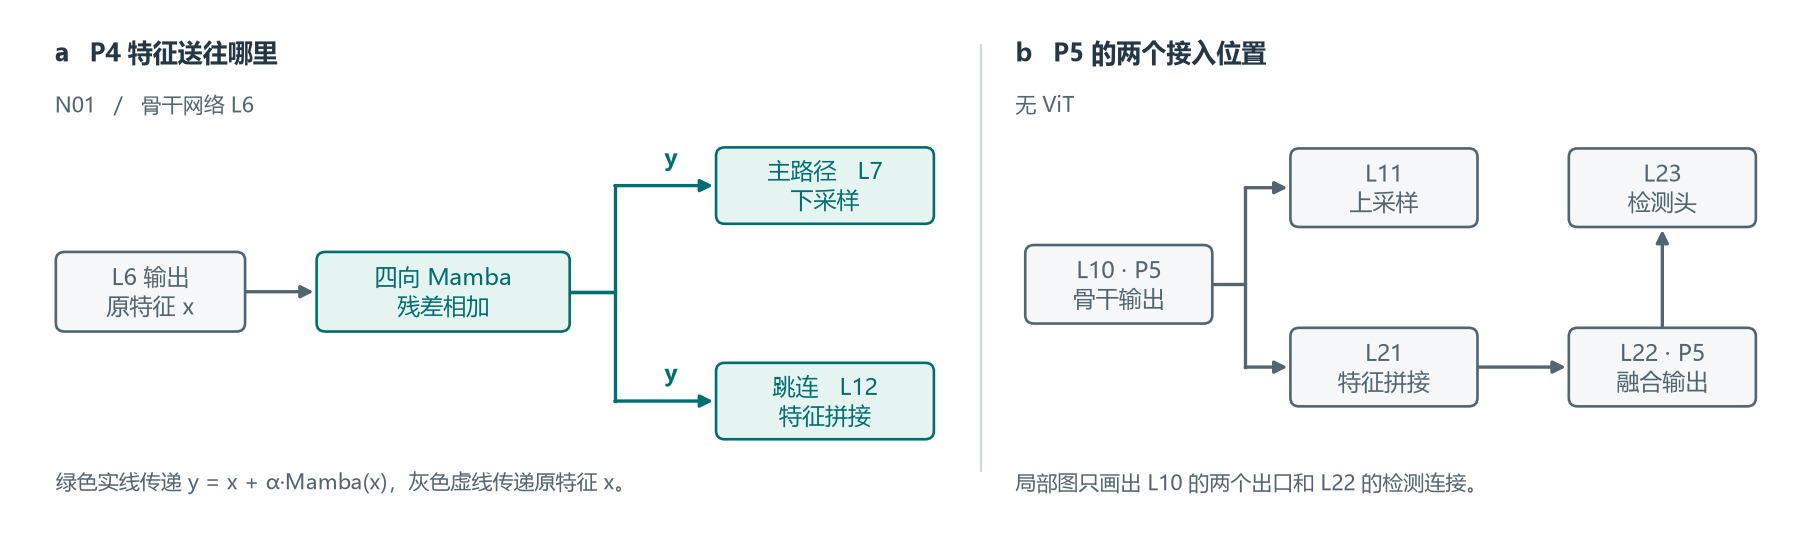

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 9,991,973


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [4]:
key = "N01"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N02 · P4 L6 双路径 + P5 L10 ViT

给 N01 的 L10 加上 ViT，就得到 N02。与 N01 比，考察早期 P5 特征加入 ViT 后的变化。与第五组比，ViT 和双路径接法相同，只有 Mamba 从 L13 移到 L6。

Overriding model.yaml nc=80 with nc=2


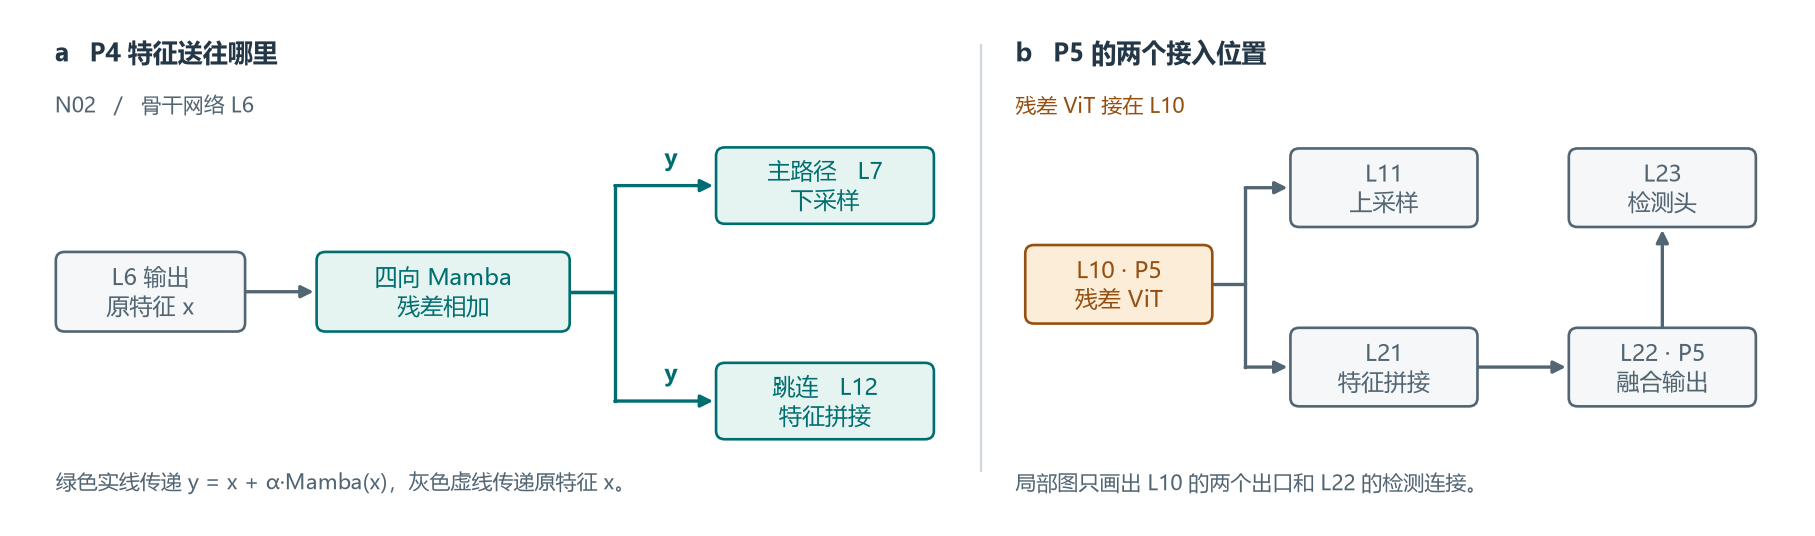

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [5]:
key = "N02"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N03 · P4 L6 双路径 + P5 L22 ViT

N02 和 N03 都在 L6 使用双路径 Mamba。两组的差别是 ViT 处理哪份 P5 特征：N02 处理骨干 L10 的输出，N03 处理即将送入检测头的 L22 输出。

Overriding model.yaml nc=80 with nc=2


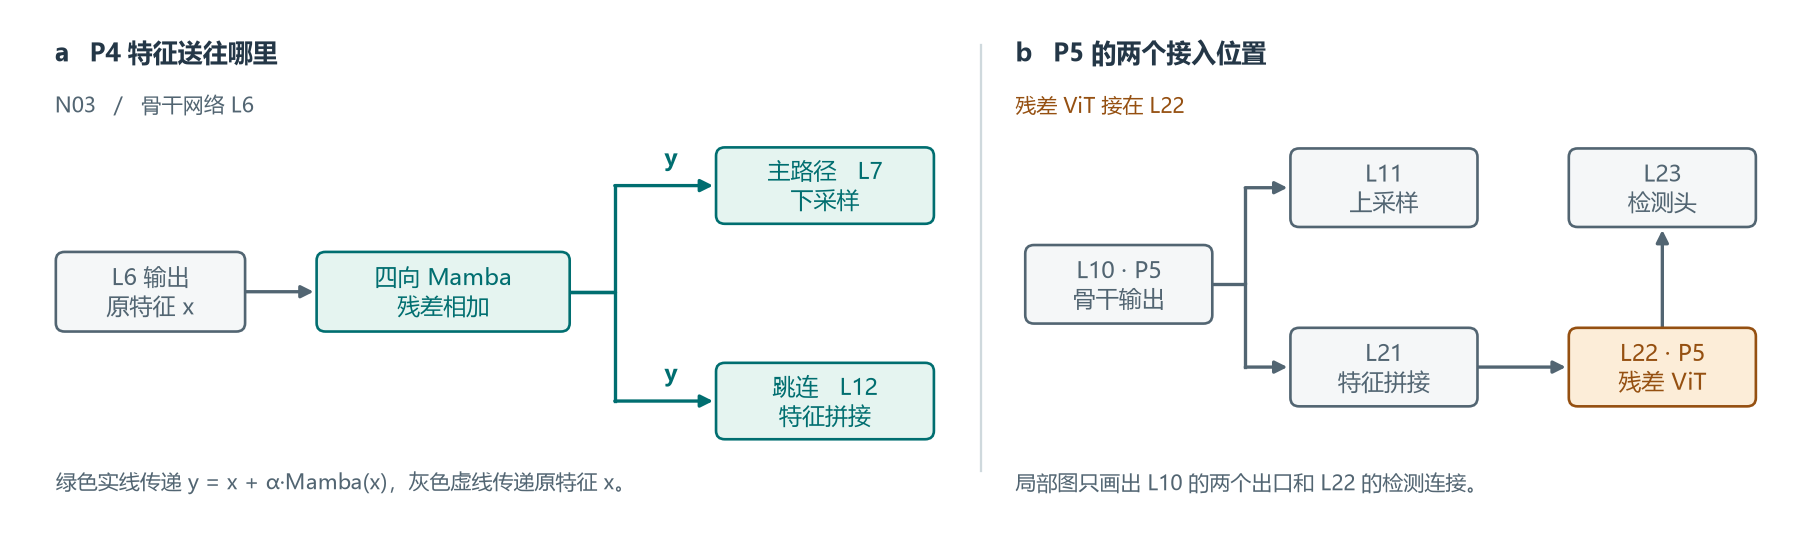

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [6]:
key = "N03"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N04 · P4 L6 仅跳连

N01 的两个出口都接收融合特征。N04 让 L7 下采样继续读取原特征，只有 L12 的拼接输入接收 Mamba 输出。两组可以直接比较主路径接收融合特征的影响。

Overriding model.yaml nc=80 with nc=2


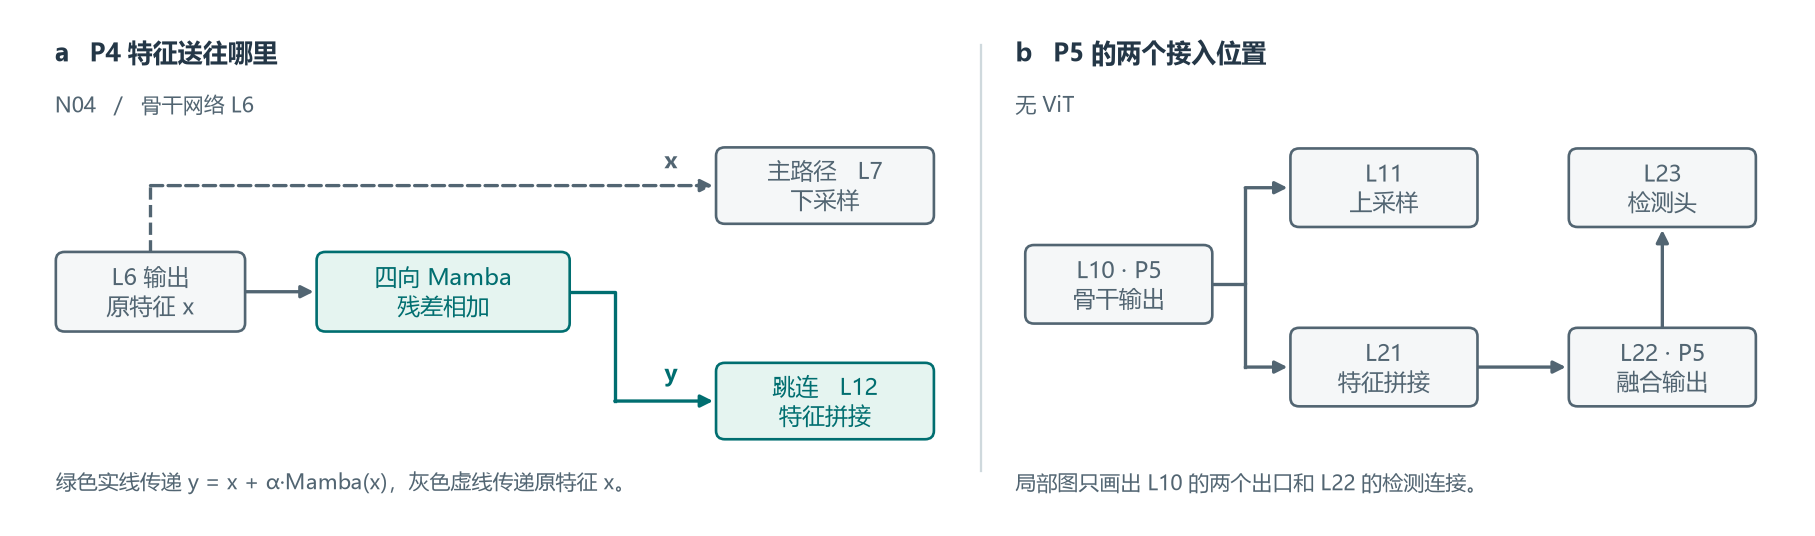

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 9,991,973


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [7]:
key = "N04"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N05 · P4 L6 仅跳连 + P5 L10 ViT

与 N02 相比，第 10 层的 ViT 保留，L7 改用原特征。再与 N04 比，Mamba 都只接跳连，这时看到的是给 L10 加上 ViT 后的差别。

Overriding model.yaml nc=80 with nc=2


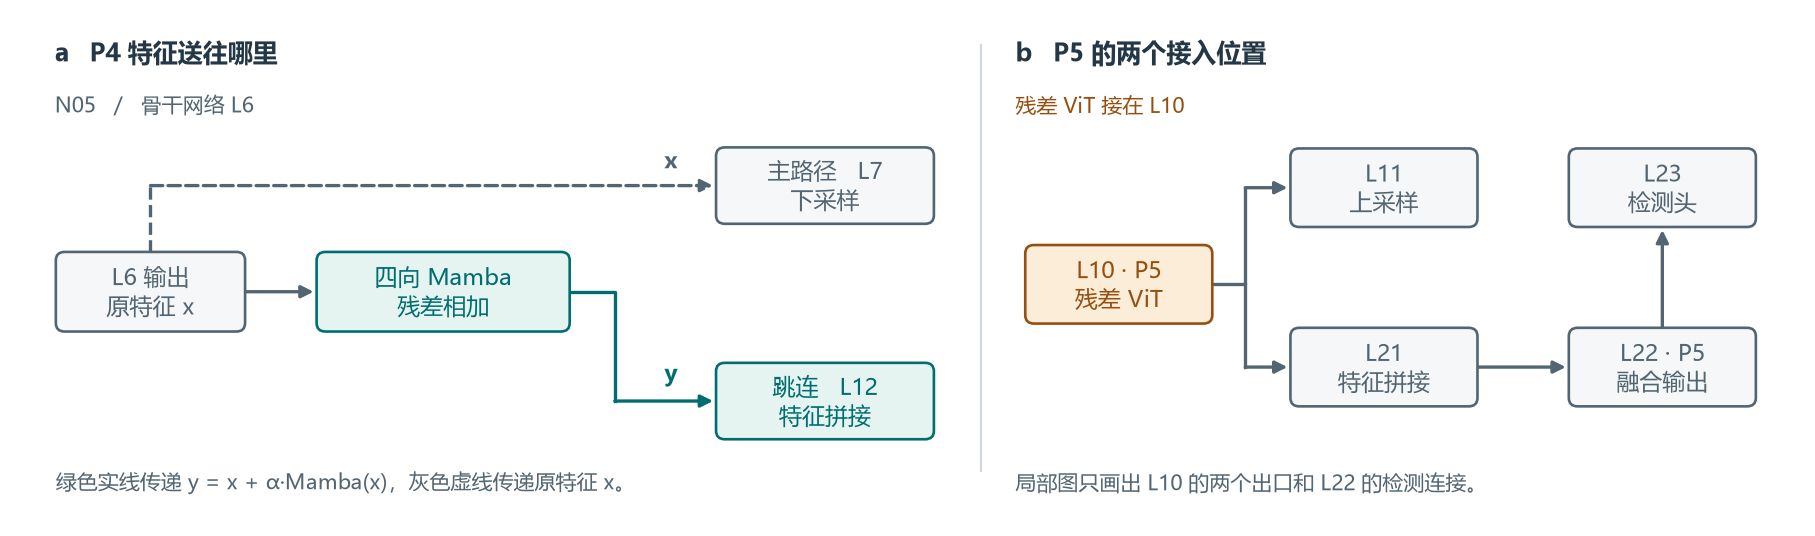

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [8]:
key = "N05"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N06 · P4 L6 仅跳连 + P5 L22 ViT

固定 L22 的 ViT，把 N06 与 N03 并排，可以比较仅跳连和双路径。若要看 ViT 的位置，比较 N06 与 N05，两组都只让 L12 接收融合特征。

Overriding model.yaml nc=80 with nc=2


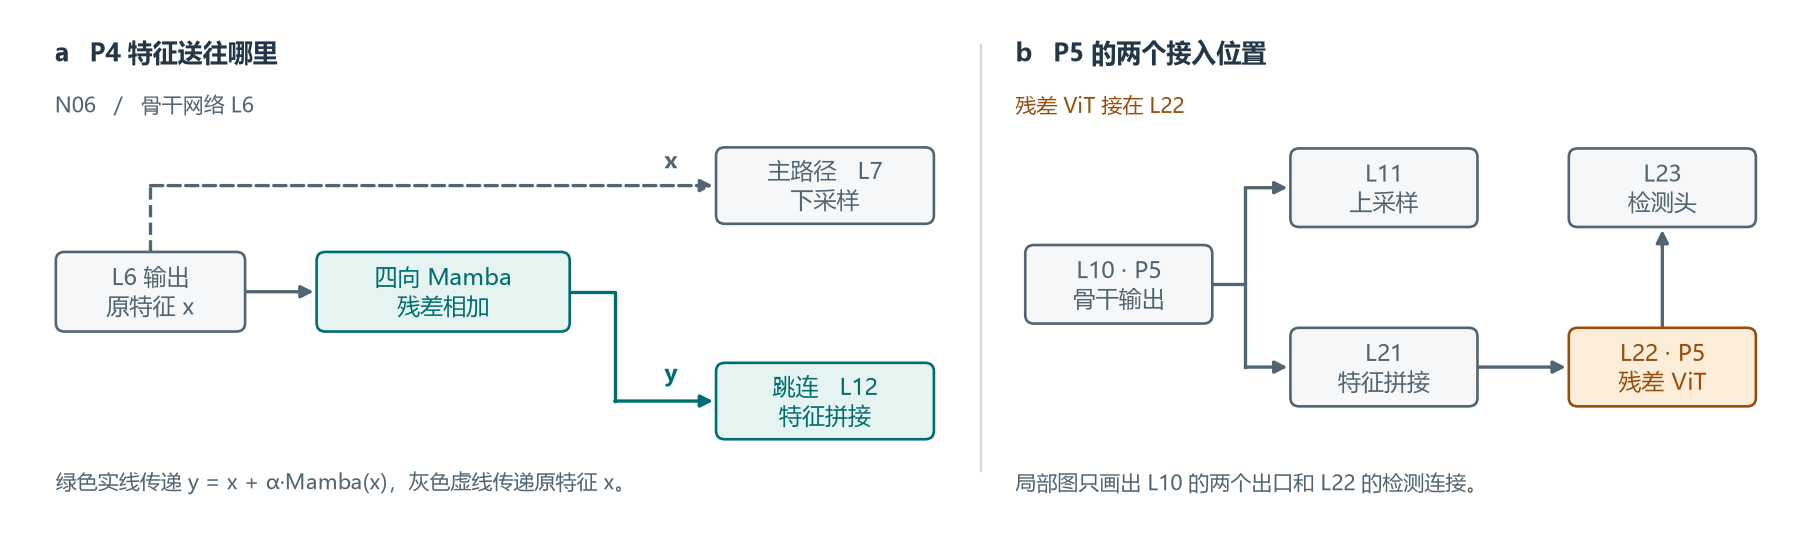

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [9]:
key = "N06"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N07 · P4 L13 双路径 + P5 L22 ViT

第五组和 N07 的 L13 Mamba 都送往 L14 和 L18。第五组在 L10 加 ViT，N07 则把同样大小的 ViT 移到 L22。两组直接比较 ViT 放在多尺度融合前或检测头前的表现。

Overriding model.yaml nc=80 with nc=2


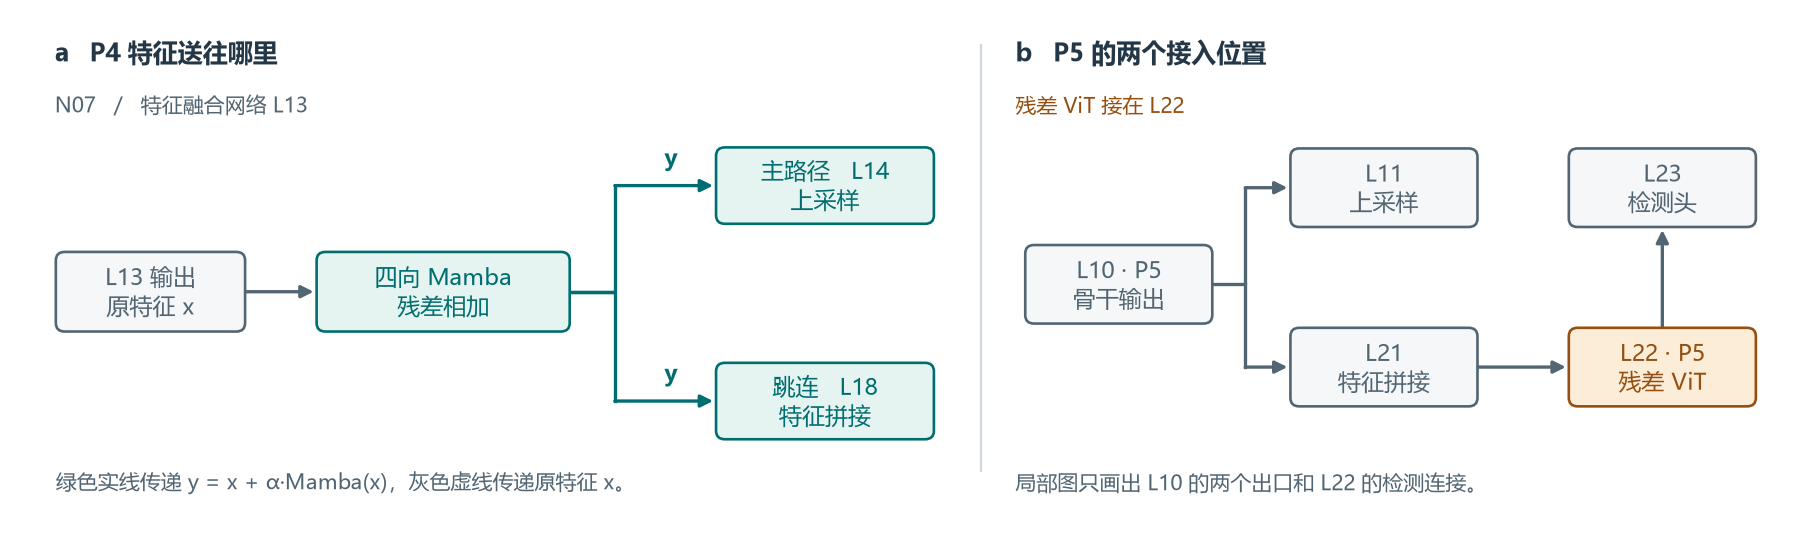

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [10]:
key = "N07"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N08 · P4 L13 仅跳连

以第四组为对照。N08 的 L18 拼接仍使用融合特征，L14 上采样改用原特征。两组均不加 ViT，便于观察上采样这一路的变化。

Overriding model.yaml nc=80 with nc=2


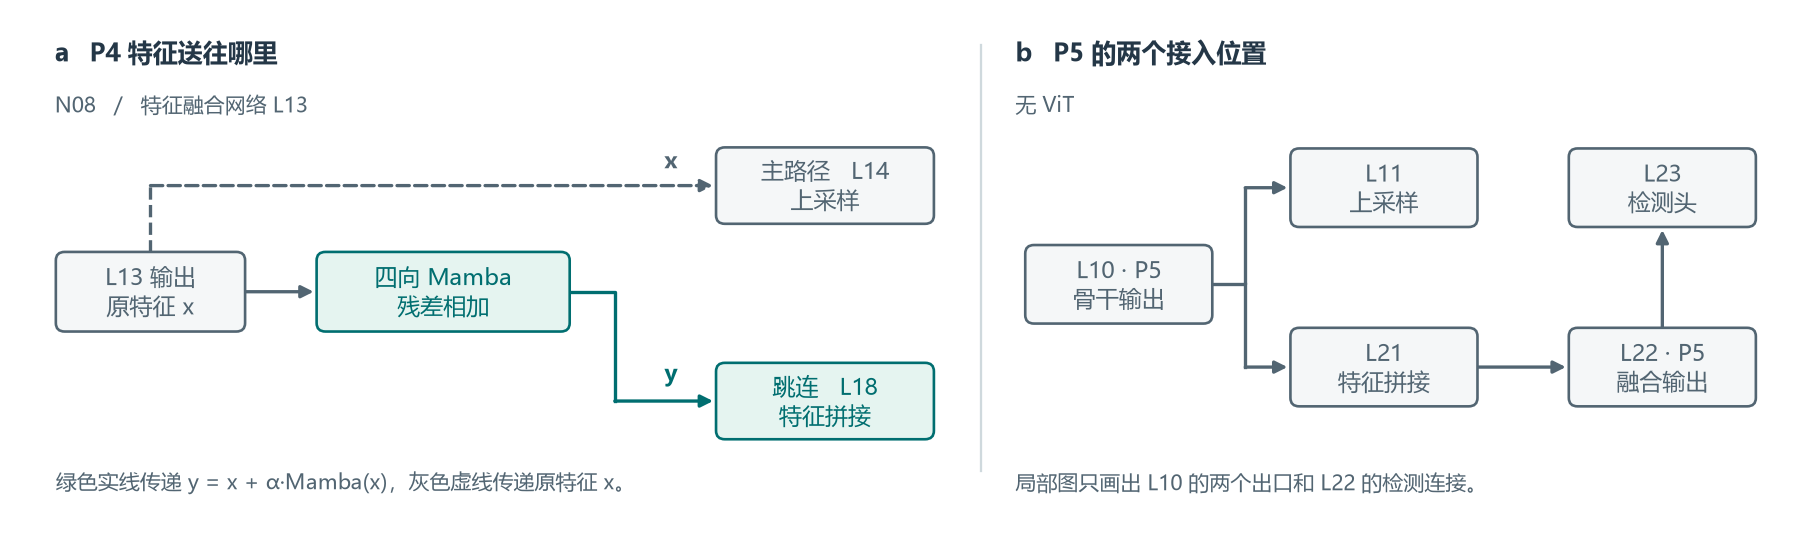

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 9,991,973


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [11]:
key = "N08"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N09 · P4 L13 仅跳连 + P5 L10 ViT

第五组和 N09 都有 L10 ViT。N09 只给 L18 拼接送融合特征，L14 上采样继续用原特征。与 N08 比，则能看到这种接法下加入 L10 ViT 的差别。

Overriding model.yaml nc=80 with nc=2


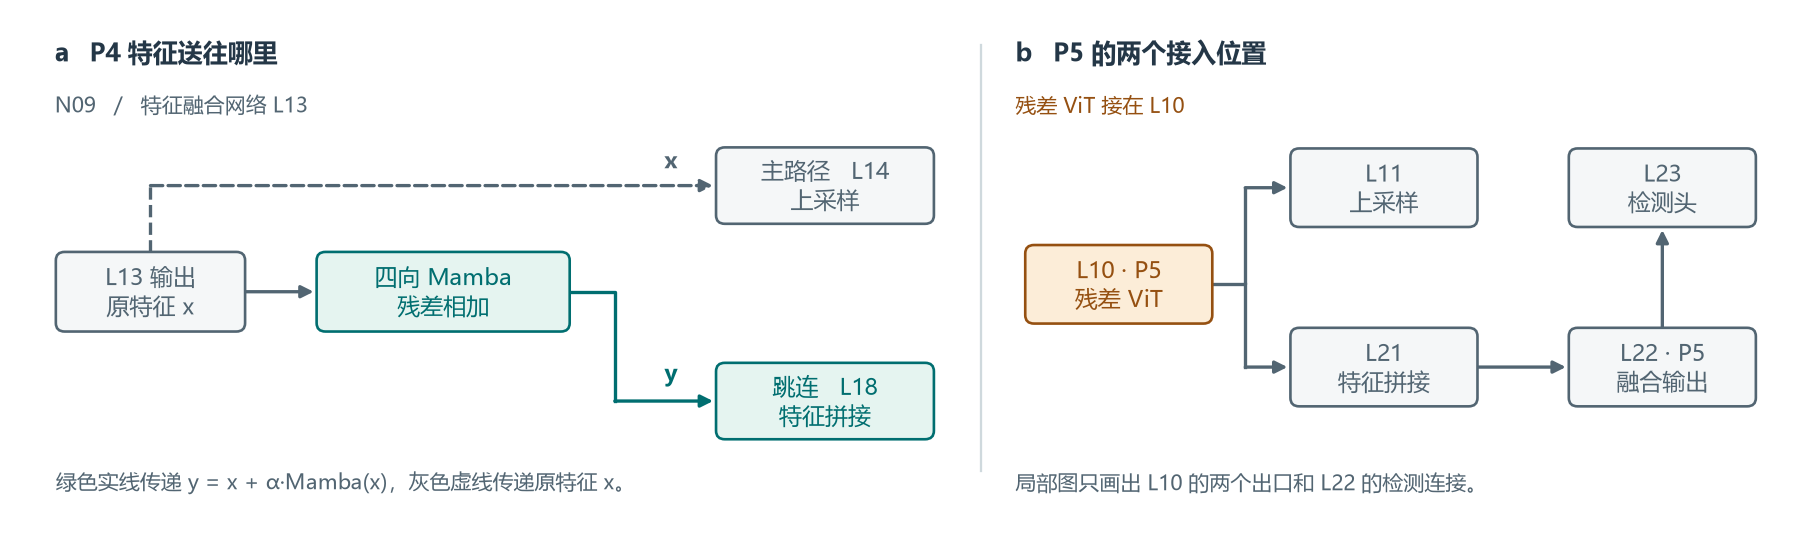

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [12]:
key = "N09"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N10 · P4 L13 仅跳连 + P5 L22 ViT

N10 只让 L18 用融合特征，并在 L22 加 ViT。与 N07 比，ViT 位置相同，可比较主路径是否也需要融合特征。与 N09 比，Mamba 接法相同，可直接比较两个 ViT 位置。

Overriding model.yaml nc=80 with nc=2


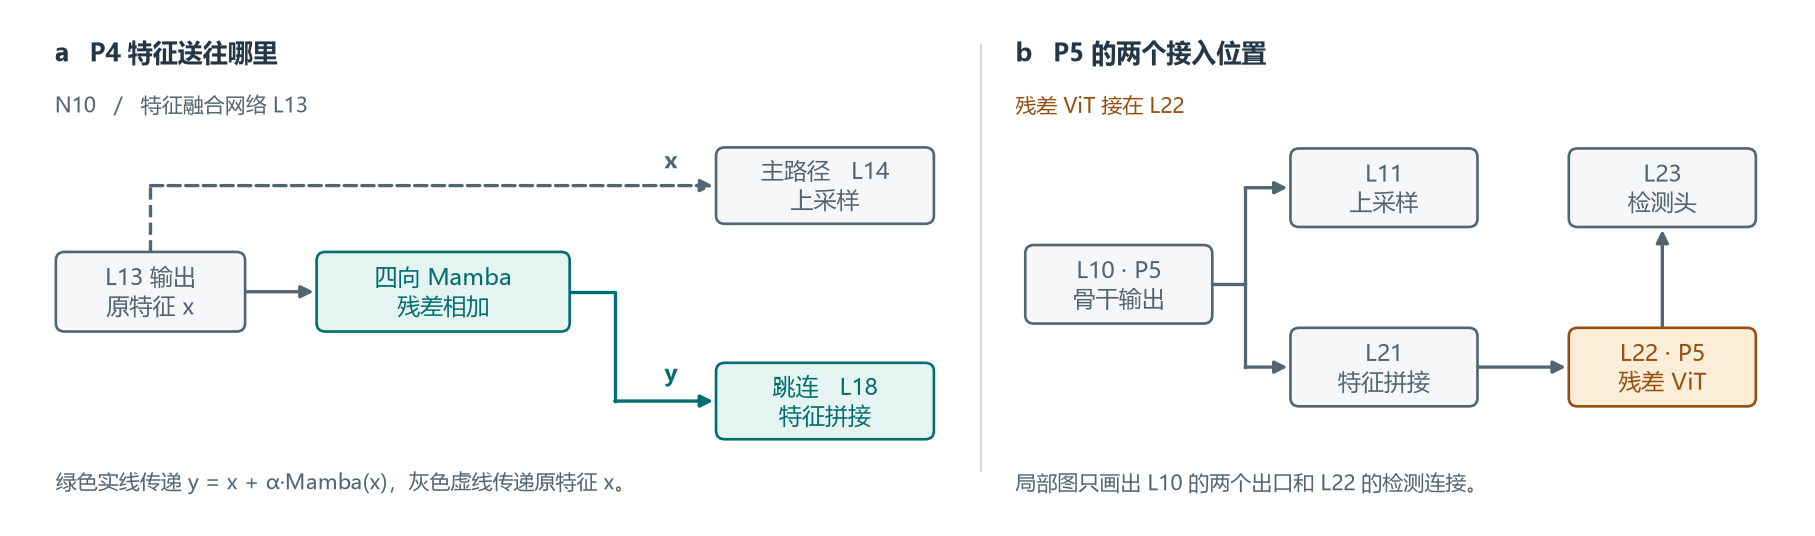

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [13]:
key = "N10"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N11 · P4 L13 仅主路径

N11 只把融合特征送给 L14 上采样，N08 只送给 L18 拼接。两组都没有 ViT。把第四组放在一起，就能比较 L13 的三种接法。

Overriding model.yaml nc=80 with nc=2


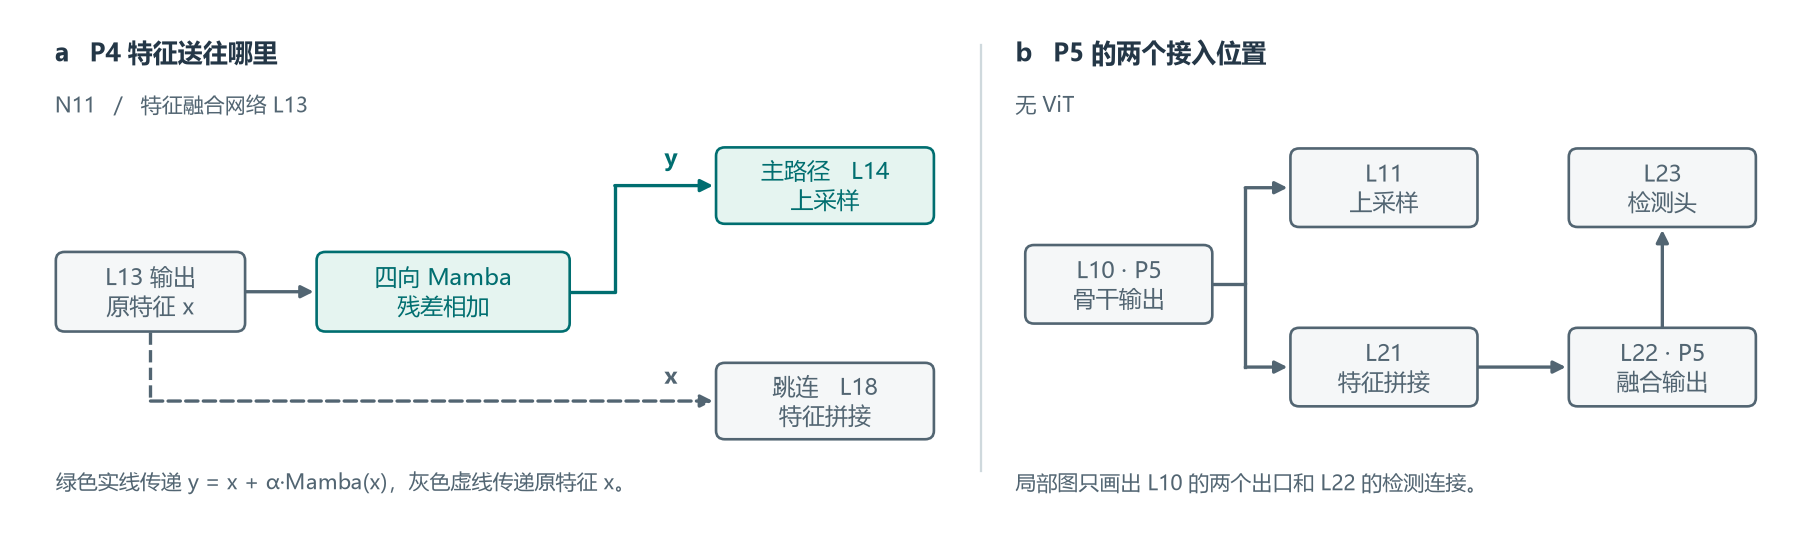

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 9,991,973


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [14]:
key = "N11"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

### N12 · P4 L13 仅主路径 + P5 L10 ViT

N12 与 N09 都在 L10 加 ViT，一个只给 L14 上采样送融合特征，另一个只给 L18 拼接送融合特征。与 N11 比，两组的 Mamba 接法相同，差别是 L10 有没有 ViT。

Overriding model.yaml nc=80 with nc=2


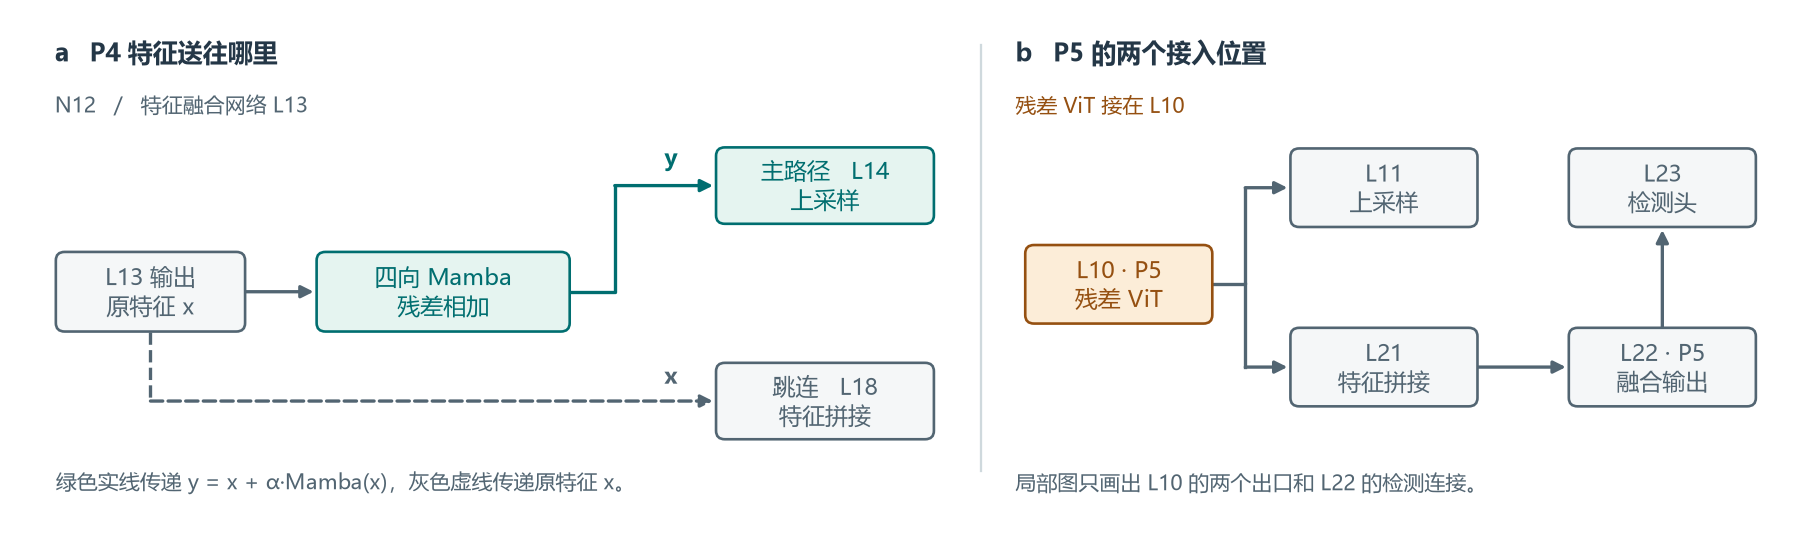

P4 (1, 256, 40, 40)  →  主路 (1, 256, 40, 40) / 跳连 (1, 256, 40, 40)
P5 (1, 512, 20, 20)  |  参数量 11,044,646


已通过：零门控等价、指定连接生效、独立进程重载与重建


In [15]:
key = "N12"
model = make_detector(defs[key], nc=2, weights=baseline)
inspect_model(key, model)

## 保存模型配置

运行下面的单元格，12 组检查全部通过后，程序会将各组的 YOLO 层结构、Mamba 路径、ViT 设置和三人的训练顺序写入 `models/fusion_phase2.yaml`。同一文件还记录了数据指纹和 COCO 初始权重的校验值。

In [16]:
assert set(verified) == set(SPECS)
saved = export(verified)
print(saved.relative_to(PROJECT))
for person, queue in GROUPS.items():
    print(person, " → ".join(queue))

models\fusion_phase2.yaml
A N07 → N10 → N01 → N05
B N08 → N11 → N02 → N06
C N09 → N12 → N03 → N04


## 三人分工与结果汇总

三台电脑使用同一份项目代码、新版数据和 YOLO26s COCO 初始权重。按 README 配好环境，确认 `models` 目录里有刚导出的 YAML 和配套 Python 模块。启动时程序会校验代码、数据、权重和训练协议。

每人用本机 GPU 0，按下表从上到下训练四组。统一设置为 `seed=0`、100 轮、输入 640 × 640、batch 4、AdamW、FP32。中断后重新执行自己的命令，程序会跳过已完成组，从中断组可用的 `last.pt` 续训。

| 批次 | A | B | C |
|---|---|---|---|
| 1 | N07 | N08 | N09 |
| 2 | N10 | N11 | N12 |
| 3 | N01 | N02 | N03 |
| 4 | N05 | N06 | N04 |

### 收齐权重后在同一台电脑复评

各人把下面目录中以自己字母命名的**整个文件夹**交给汇总人。这样既能核对权重，也能查到训练设备和中断轮次。

`training/artifacts/studies/760e212a7ba42aaf20b2f912aaa688c72c01bbc6c4eacd7af771866161605e8b/phase2/`

汇总人把 A、B、C 放到本机的同一目录，并备好第一轮基线、第四组、第五组的训练记录和权重。关闭正在打开的实验工作簿，在项目根目录运行下面的命令。

```powershell
& .\.venv-cuda\Scripts\python.exe -m models.phase2 review --device 0 --data training/configs/study-data.yaml
```

### 从 14 个候选里选一个

原版 YOLO26s 提供艇的 AP50 门槛。参加排名的是第四组、第五组和本轮 12 个新模型。复评程序用同一张卡评估各组的 `best.pt`，按未四舍五入的指标选优。

1. 保留车的 AP50 至少达到第四组、艇的 AP50 至少达到原版 YOLO26s 的候选。第一轮测得的两个参考值约为 92.26% 和 81.58%。
2. 在达标组中选 Overall mAP50 最高者。如果相同，先选艇的 AP50–95 更高者，再选同一张卡上推理延迟更低者。若 14 组都未同时达标，仍列出 Overall 第一名，并注明未达到哪项门槛。

复评结果写入原工作簿的「第二轮14组对比」。各组的详细指标、训练设备和续训轮次保存在 `phase2/review/comparison.json`。

两类目标各占 Overall mAP50 的一半。按车的 AP50 为 92.26% 计算，艇需达到约 87.74%，两类平均才到 90%。最终成绩来自同一批 93 张验证图和一个训练种子，在这些图上选出的第一名仍需独立数据检验。

## 每位同学的训练命令

在各自电脑的项目根目录打开 PowerShell，复制自己名字下面的那一行。

```powershell
# 同学 A：N07 → N10 → N01 → N05
& .\.venv-cuda\Scripts\python.exe -m models.phase2 A --device 0 --data training/configs/study-data.yaml

# 同学 B：N08 → N11 → N02 → N06
& .\.venv-cuda\Scripts\python.exe -m models.phase2 B --device 0 --data training/configs/study-data.yaml

# 同学 C：N09 → N12 → N03 → N04
& .\.venv-cuda\Scripts\python.exe -m models.phase2 C --device 0 --data training/configs/study-data.yaml
```